# Семинар 2. Pipeline, spaCy и Hugging Face Datasets

На прошлом семинаре мы познакомились с базовым NLP-pipeline:

```text
текст → preprocessing → TF-IDF → Logistic Regression
```

Теперь перейдём к новым инструментам и более профессиональной организации NLP-эксперимента.

### План семинара

1. **`sklearn.Pipeline`**
   - зачем объединять preprocessing и модель;
   - как Pipeline помогает избежать ошибок;
   - cross-validation;
   - `GridSearchCV`;
   - подбор гиперпараметров.

2. **spaCy**
   - `nlp`, `Doc`, `Token`, `Span`;
   - леммы и части речи;
   - синтаксические зависимости;
   - Named Entity Recognition.

3. **Hugging Face Datasets**
   - загрузка датасетов;
   - splits;
   - `Dataset`;
   - `IterableDataset`;
   - streaming.

> Главная цель семинара — перейти от отдельных операций над текстом к более цельному и воспроизводимому NLP workflow.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from pathlib import Path


RANDOM_STATE = 42


## Данные для примеров

Для блока с `Pipeline` используем тот же RuTweetCorp, что и на первом семинаре.

Нам понадобятся только:

```text
text     — текст твита
positive — target: 1 / 0
```

Если `positive.csv` и `negative.csv` уже загружены в Colab, достаточно выполнить следующую ячейку.


In [3]:
DATA_PATH = Path('/home/fedosdan2/Study/NLP/2/data')

def load_rutweet(path, target):
    df = pd.read_csv(
        path,
        sep=None,
        engine='python',
        header=None,
        encoding='utf-8'
    )

    if df.shape[1] <= 3:
        raise ValueError(
            f'В {path} найдено {df.shape[1]} столбцов. '
            'Проверьте формат файла.'
        )

    return pd.DataFrame({
        'text': df.iloc[:, 3].astype(str),
        'positive': target
    })

positive = load_rutweet(DATA_PATH / 'positive.csv', 1)
negative = load_rutweet(DATA_PATH / 'negative.csv', 0)

data = pd.concat([positive, negative], ignore_index=True)

X_train, X_test, y_train, y_test = train_test_split(
    data['text'],
    data['positive'],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=data['positive']
)

print('Train:', X_train.shape)
print('Test :', X_test.shape)


Train: (181468,)
Test : (45368,)


## 1. Зачем нужен Pipeline?

До сих пор мы писали:

```python
tfidf.fit_transform(X_train)
model.fit(...)
tfidf.transform(X_test)
model.predict(...)

TRAIN:
fit → transform → fit model

TEST:
transform → predict
```

Это полезно для понимания механики.

Но в реальном ML-проекте появляется риск:

- случайно сделать `fit` на test;
- применить разные преобразования к train и test;
- запутаться при cross-validation; - Вопрос что это такое?
- забыть один из шагов при inference.

`Pipeline` объединяет преобразования и модель в **один объект**.

In [4]:
from sklearn.pipeline import Pipeline


classifier = Pipeline([
    (
        'vectorizer',
        TfidfVectorizer(min_df=2)
    ),
    (
        'model',
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

classifier

,steps,"[('vectorizer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


Теперь весь процесс выглядит так:

```text
raw text
   ↓
TfidfVectorizer
   ↓
LogisticRegression
```

И снаружи мы работаем с ним как с обычной моделью.

In [5]:
classifier.fit(X_train, y_train)

pipeline_pred = classifier.predict(X_test)

print(
    'F1:',
    round(f1_score(y_test, pipeline_pred), 4)
)

F1: 0.7667


## 2. Cross-validation

Кросс-валидация — это несколько внутренних проверок на train-данных.

Один train/test split зависит от конкретного разбиения данных.

Cross-validation несколько раз меняет validation-часть:

```text
Fold 1: train train train train | valid
Fold 2: train train train valid | train
Fold 3: train train valid train | train
...
```
```text
Допустим, у нас есть 12 объектов.

Fold 1: [1 2 3 4]       → validation
        [5 6 7 8 9 10 11 12] → train

Fold 2: [5 6 7 8]       → validation
        остальные       → train

Fold 3: [9 10 11 12]    → validation
        остальные       → train
```
В результате мы получаем более устойчивую оценку качества.

In [6]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    classifier,
    X_train,
    y_train,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1
)

print('F1 по folds:', cv_scores.round(4))
print('Средний F1:', round(cv_scores.mean(), 4))
print('Std:', round(cv_scores.std(), 4))

F1 по folds: [0.7513 0.751  0.7521]
Средний F1: 0.7515
Std: 0.0005


### Зачем смотреть стандартное отклонение?

Две модели могут иметь одинаковый средний F1:

```text
Model 1: 0.91 ± 0.01
Model 2: 0.91 ± 0.08
```

Но первая модель работает значительно **стабильнее** на разных разбиениях.

## 3. GridSearchCV

**GridSearchCV - Метод автоматического подбора гиперпараметров модели, который перебирает заданные комбинации параметров и оценивает каждую из них с помощью cross-validation.**


У модели и preprocessing есть гиперпараметры.

Например:

### `TfidfVectorizer`

- `ngram_range` — какие n-граммы использовать.  
  `(1, 1)` — только отдельные слова, `(1, 2)` — слова + пары слов.

- `min_df` — минимальное количество документов, в которых должен встретиться термин, чтобы попасть в словарь.  
  Помогает убрать очень редкие слова.

- `max_df` — максимальная доля документов, в которых может встречаться термин.  
  Помогает убрать слишком частые, малоинформативные слова.

### `LogisticRegression`

- `C` — обратная сила регуляризации.  
  Чем меньше `C`, тем сильнее регуляризация.

- `penalty` — тип регуляризации: например `l1` или `l2`.

- `solver` — алгоритм оптимизации, который ищет веса модели.

### Важный момент про `C`

В `LogisticRegression`:

```text
маленький C → сильнее регуляризация
большой C   → слабее регуляризация
```

Регуляризация ограничивает слишком большие коэффициенты модели и помогает бороться с переобучением.

In [ ]:
from sklearn.model_selection import GridSearchCV

grid_pipeline = Pipeline([
    (
        'vectorizer',
        TfidfVectorizer(min_df=2)
    ),
    (
        'model',
        LogisticRegression(
            solver='liblinear',
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

param_grid = {
    'vectorizer__ngram_range': [
        (1, 1),
        (1, 2)
    ],
    'model__C': [
        0.3,
        1.0,
        3.0
    ],
    'model__penalty': [
        'l1',
        'l2'
    ]
}

grid = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    verbose=1,
    refit=True
)

> На учебном ноутбуке grid специально небольшой.

В реальном проекте не стоит бездумно запускать огромный перебор: - Кто скажет почему?

```text
10 параметров × 10 значений × 5 folds
```


In [8]:
grid.fit(X_train, y_train)

print('Лучшие параметры:')
print(grid.best_params_)

print('\nЛучший CV F1:')
print(round(grid.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Лучшие параметры:
{'model__C': 3.0, 'model__penalty': 'l2', 'vectorizer__ngram_range': (1, 2)}

Лучший CV F1:
0.7667


In [9]:
best_pred = grid.best_estimator_.predict(X_test)

print(
    'Test F1:',
    round(f1_score(y_test, best_pred), 4)
)

Test F1: 0.7842


### Задание

Попробуйте добавить в `param_grid`:

```python
'vectorizer__min_df': [1, 2, 5]
```

Ответьте:

1. какой набор параметров оказался лучшим;
2. насколько изменился F1;
3. стоит ли усложнение модели полученного прироста?

In [10]:
from sklearn.model_selection import GridSearchCV

grid_pipeline = Pipeline([
    (
        'vectorizer',
        TfidfVectorizer(min_df=2)
    ),
    (
        'model',
        LogisticRegression(
            solver='liblinear',
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

param_grid = {
    'vectorizer__ngram_range': [
        (1, 1),
        (1, 2)
    ],
    'vectorizer__min_df': [
        1, 
        2, 
        5
    ], 
    'model__C': [
        0.3,
        1.0,
        3.0
    ],
    'model__penalty': [
        'l1',
        'l2'
    ]
}

grid = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [11]:
grid.fit(X_train, y_train)

print('Лучшие параметры:')
print(grid.best_params_)

print('\nЛучший CV F1:')
print(round(grid.best_score_, 4))

best_pred = grid.best_estimator_.predict(X_test)

print(
    'Test F1:',
    round(f1_score(y_test, best_pred), 4)
)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Лучшие параметры:
{'model__C': 3.0, 'model__penalty': 'l2', 'vectorizer__min_df': 1, 'vectorizer__ngram_range': (1, 2)}

Лучший CV F1:
0.7689
Test F1: 0.7857


---
# Часть 2. spaCy: текст как структурированный объект

До сих пор мы в основном работали с текстом как со строкой:

```python
"Я люблю обработку естественного языка"
```

Но в NLP часто нужно знать больше:

- где находятся токены;
- какая у слова лемма;
- какая часть речи;
- от какого слова оно зависит;
- является ли фрагмент именованной сущностью.

Для таких задач удобно использовать **spaCy**.

bcdfffe5c0b9f221a2f6607f96ca0e4a.svg




## 4. Установка spaCy и русского pipeline

In [12]:
!pip -q install spacy
!python -m spacy download ru_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 7.0 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 9.7 MB/s  0:00:00 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ru-core-news-sm] [ru-core-news-sm]
✔ Download and installation successful
You can now load the package via spacy.load('ru_core_news_sm')


In [13]:
import spacy

nlp = spacy.load('ru_core_news_sm')

print(nlp.pipe_names)

['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## 5. `nlp` и `Doc`

`nlp` — объект, который содержит pipeline обработки текста.

Передаём ему строку:

```python
doc = nlp(text)
```

и получаем объект `Doc`.

In [14]:
doc = nlp(
    'Студенты изучают обработку естественного языка в университете.'
)

print(type(doc))

for token in doc:
    print(token.text)

<class 'spacy.tokens.doc.Doc'>
Студенты
изучают
обработку
естественного
языка
в
университете
.


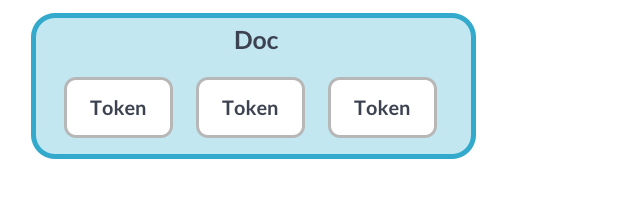

## 6. `Token`

`Doc` можно представить как последовательность токенов.

Каждый `Token` содержит не только текст слова, но и множество дополнительных атрибутов.

In [15]:
token = doc[0]

print('text      =', token.text)
print('lemma     =', token.lemma_)
print('POS       =', token.pos_)
print('is_alpha  =', token.is_alpha)
print('is_punct  =', token.is_punct)
print('like_num  =', token.like_num)

text      = Студенты
lemma     = студент
POS       = NOUN
is_alpha  = True
is_punct  = False
like_num  = False


### Что означают атрибуты `Token`

- `token.text` — исходный текст токена.
- `token.lemma_` — лемма, то есть нормальная форма слова.
- `token.pos_` — часть речи: существительное, глагол, прилагательное и т.д.
- `token.is_alpha` — состоит ли токен только из букв.
- `token.is_punct` — является ли токен знаком пунктуации.
- `token.like_num` — похож ли токен на число.

### Задание

Выведите для каждого токена:

```text
text
lemma_
pos_
is_stop
```

Какие слова spaCy считает стоп-словами?

In [18]:
for token in doc:
    print('text      =', token.text)
    print('lemma     =', token.lemma_)
    print('POS       =', token.pos_)
    print('is_stop  =', token.is_stop)
    print('-------------------------')


text      = Студенты
lemma     = студент
POS       = NOUN
is_stop  = False
-------------------------
text      = изучают
lemma     = изучать
POS       = VERB
is_stop  = False
-------------------------
text      = обработку
lemma     = обработка
POS       = NOUN
is_stop  = False
-------------------------
text      = естественного
lemma     = естественный
POS       = ADJ
is_stop  = False
-------------------------
text      = языка
lemma     = язык
POS       = NOUN
is_stop  = False
-------------------------
text      = в
lemma     = в
POS       = ADP
is_stop  = True
-------------------------
text      = университете
lemma     = университет
POS       = NOUN
is_stop  = False
-------------------------
text      = .
lemma     = .
POS       = PUNCT
is_stop  = False
-------------------------


## 7. `Span`

`Span` — это срез `Doc`, содержащий несколько токенов.

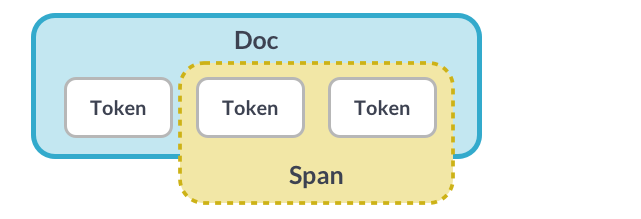

In [19]:
span = doc[2:5]

print(span.text)
print(type(span))

обработку естественного языка
<class 'spacy.tokens.span.Span'>


## 8. Лемматизация и части речи

В первом семинаре мы использовали отдельный инструмент для лемматизации.

spaCy позволяет одновременно получить:

```text
токен → лемма → часть речи
```

In [20]:
doc = nlp(
    'Красивые машины быстро ехали по заснеженной дороге.'
)

for token in doc:
    print(
        f'{token.text:15}',
        f'{token.lemma_:15}',
        token.pos_
    )

Красивые        красивый        ADJ
машины          машина          NOUN
быстро          быстро          ADV
ехали           ехать           VERB
по              по              ADP
заснеженной     заснеженной     VERB
дороге          дорога          NOUN
.               .               PUNCT


### Основные значения `POS`

1. `NOUN` — существительное  
2. `VERB` — глагол  
3. `ADJ` — прилагательное  
4. `ADV` — наречие  
5. `PRON` — местоимение  
6. `PROPN` — имя собственное  
7. `NUM` — числительное  
8. `PUNCT` — пунктуация

## 9. Синтаксические зависимости

`dep_` показывает синтаксическое отношение слова.

`head` — слово, от которого текущий токен зависит.

In [21]:
doc = nlp(
    'Студенты внимательно слушают преподавателя.'
)

for token in doc:
    print(
        token.text,
        '→',
        token.dep_,
        '→ head:',
        token.head.text
    )

Студенты → nsubj → head: слушают
внимательно → advmod → head: слушают
слушают → ROOT → head: слушают
преподавателя → obj → head: слушают
. → punct → head: слушают


## Шпаргалка: `POS` и `dep_` в spaCy

### Части речи — `token.pos_`

| Обозначение | Значение | Пример |
|---|---|---|
| `NOUN` | существительное | `студент`, `машина` |
| `VERB` | глагол | `слушать`, `ехать` |
| `ADJ` | прилагательное | `красивый`, `быстрый` |
| `ADV` | наречие | `внимательно`, `быстро` |
| `PRON` | местоимение | `я`, `он`, `они` |
| `PROPN` | имя собственное | `Москва`, `Яндекс` |
| `NUM` | числительное | `один`, `12` |
| `PUNCT` | пунктуация | `.`, `,`, `!` |

---

### Синтаксические зависимости — `token.dep_`

| Обозначение | Значение | Пример |
|---|---|---|
| `ROOT` | главное слово предложения | `слушают` |
| `nsubj` | подлежащее | `Студенты → слушают` |
| `obj` | дополнение | `преподавателя → слушают` |
| `advmod` | обстоятельство / наречный модификатор | `внимательно → слушают` |
| `amod` | определение-прилагательное | `красивый → дом` |
| `nmod` | именная модификация | `студента → книга` |
| `obl` | обстоятельственное дополнение | `в Москву → ехать` |
| `case` | предлог / показатель падежной связи | `в → Москву` |
| `conj` | однородный член | `кофе → чай` |
| `cc` | сочинительный союз | `и`, `или`, `но` |
| `aux` | вспомогательный глагол | вспомогательная глагольная форма |
| `cop` | глагол-связка | `быть`, `являться` |
| `mark` | подчинительный союз | `что`, `если`, `когда` |
| `punct` | знак пунктуации | `.`, `,`, `!` |
| `xcomp` | зависимая конструкция без собственного подлежащего | `хочу работать` |
| `ccomp` | придаточная часть с собственным подлежащим | `знаю, что он придёт` |

> `token.pos_` отвечает на вопрос **«какая это часть речи?»**  
> `token.dep_` отвечает на вопрос **«какую синтаксическую роль этот токен играет?»**  
> `token.head` показывает, **от какого слова он зависит**.

In [22]:
from spacy import displacy

displacy.render(
    doc,
    style='dep',
    jupyter=True
)

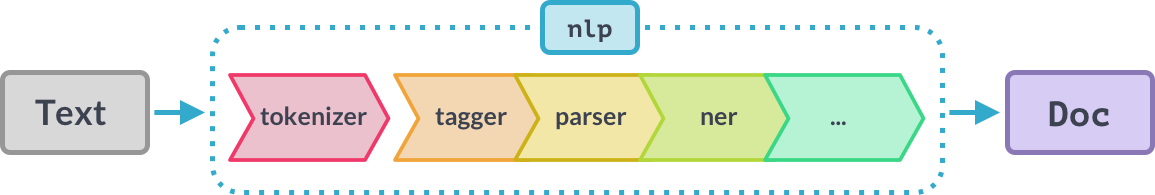

## 10. Named Entity Recognition

NER — задача поиска сущностей в тексте.

Например:

```text
Москва      → LOC
Александр   → PER
Сбербанк    → ORG
```

In [23]:
doc = nlp(
    'Александр приехал из Москвы и устроился работать в Яндекс.'
)

for ent in doc.ents:
    print(
        ent.text,
        ent.label_,
        spacy.explain(ent.label_)
    )

Александр PER Named person or family.
Москвы LOC Non-GPE locations, mountain ranges, bodies of water
Яндекс ORG Companies, agencies, institutions, etc.


In [24]:
displacy.render(
    doc,
    style='ent',
    jupyter=True
)

### Задание

Возьмите любое короткое новостное предложение и:

1. найдите все токены;
2. выведите леммы;
3. выведите части речи;
4. найдите именованные сущности;
5. визуализируйте зависимости.

In [32]:
string = 'Александр приехал из Питера.'

doc = nlp(string)

for token in doc:
    print(
        f'{token.text:15}',
        f'{token.lemma_:15}',
        f'{token.pos_:10}',
        f'{token.ent_type_:10}',
        spacy.explain(token.ent_type_) if token.ent_type_ else ''
    )
    print('------------------------')

displacy.render(
    doc,
    style='ent',
    jupyter=True
)

Александр       александр       PROPN      PER        Named person or family.
------------------------
приехал         приехать        VERB                  
------------------------
из              из              ADP                   
------------------------
Питера          питер           PROPN      LOC        Non-GPE locations, mountain ranges, bodies of water
------------------------
.               .               PUNCT                 
------------------------


### Что важно понять про spaCy

spaCy не заменяет TF-IDF или классификатор.

Это другой уровень NLP-инструментария.


TF-IDF
→ статистическая мера, которая показывает, насколько важно слово для конкретного документа внутри большого набора документов (корпуса). Знание меры позволяет базово векторизвать текст

spaCy
→ структурированный лингвистический анализ текста в котором учитывается не только частота, а так же морфологический, лингвистический анализ и взаимосвязи слов в тексте


В реальном проекте эти подходы могут использоваться вместе.
### Список типов именованных сущностей

Полное описание Named Entity Recognition и основных типов сущностей можно посмотреть в официальной документации spaCy:

[spaCy — Named Entity Recognition](https://spacy.io/usage/linguistic-features#named-entities)

Например:

- `PER` / `PERSON` — человек;
- `ORG` — организация;
- `LOC` — географическая локация;
- `GPE` — страна, город, регион;
- `MONEY` — денежное значение;
- `DATE` — дата;
- `TIME` — время.

> Набор доступных `label` зависит от конкретной языковой модели spaCy.

---
# Часть 3. Hugging Face Datasets

# Hugging Face Datasets

Официальная документация библиотеки:

[Hugging Face Datasets — Documentation](https://huggingface.co/docs/datasets/index)

Полезные разделы:

- [Loading datasets](https://huggingface.co/docs/datasets/loading)
- [Dataset object](https://huggingface.co/docs/datasets/package_reference/main_classes#datasets.Dataset)
- [Streaming](https://huggingface.co/docs/datasets/stream)

## 11. Зачем Hugging Face?

До сих пор датасеты лежали у нас локально:

```text
positive.csv
negative.csv
```

Но в ML существует большое количество публичных датасетов и моделей.

**Hugging Face** — одна из основных платформ современной NLP/ML-экосистемы.

Библиотека `datasets` позволяет:

- находить и загружать датасеты;
- работать со splits-отдельные части тренировочной/валидационной/тестовой выборки;
- быстро применять преобразования;
- читать большие датасеты потоково.

In [ ]:
!pip -q install datasets

## 12. Смотрим описание датасета до загрузки

In [ ]:
from datasets import load_dataset_builder

builder = load_dataset_builder(
    'cornell-movie-review-data/rotten_tomatoes'
)

print(builder.info.description[:1000])
print(builder.info.features)

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]


{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


## 13. Загружаем Dataset

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    'cornell-movie-review-data/rotten_tomatoes',
    split='train'
)

dataset

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 8530
})

In [ ]:
dataset[0]

{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
 'label': 1}

In [ ]:
dataset[:3]

{'text': ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .',
  'effective but too-tepid biopic'],
 'label': [1, 1, 1]}

`Dataset` похож на таблицу, но оптимизирован для ML-задач.

Можно получать:

- отдельную строку;
- срез;
- столбец;
- применять преобразования через `.map()`.

## 14. Splits

У ML-датасета часто уже есть:

```text
train
validation
test
```

In [ ]:
from datasets import get_dataset_split_names

get_dataset_split_names('cornell-movie-review-data/rotten_tomatoes')

['train', 'validation', 'test']

### Почему готовые splits полезны?

Если авторы датасета заранее зафиксировали train/test:

- эксперименты разных людей легче сравнивать;
- уменьшается вероятность случайно получить «удобное» разбиение;
- benchmark становится воспроизводимым.

## 15. Dataset → pandas

In [ ]:
small_dataset = dataset.select(range(100))

df_hf = small_dataset.to_pandas()

df_hf.head()

,text,label
0,the rock is destined to be the 21st century's ...,1
1,"the gorgeously elaborate continuation of "" the...",1
2,effective but too-tepid biopic,1
3,if you sometimes like to go to the movies to h...,1
4,"emerges as something rare , an issue movie tha...",1


То есть Hugging Face Datasets не отменяет привычный `pandas`.

Обычно мы выбираем инструмент под задачу:

```text
pandas
→ табличный анализ и EDA

datasets.Dataset
→ ML/NLP pipeline и большие наборы данных
```

## 16. `IterableDataset`

Обычный `Dataset` предоставляет произвольный доступ:

```python
dataset[100]
```

Но очень большой датасет может не помещаться в память.

Тогда используется потоковая обработка:

```text
данные → по одному объекту → обработка
```

In [ ]:
iterable_dataset = dataset.to_iterable_dataset()

first_three = list(iterable_dataset.take(3))

first_three

[{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'label': 1},
 {'text': 'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .',
  'label': 1},
 {'text': 'effective but too-tepid biopic', 'label': 1}]

В реальном streaming-сценарии датасет можно читать с удалённого источника, не загружая его полностью.

Это особенно полезно для:

- больших корпусов;
- обучения language models;
- пайплайнов, где данные обрабатываются последовательно.

### Задание

Для любого другого датасета из пространства Hugging Face:

1. получите список доступных splits;
2. загрузите `test`;
3. выведите 5 случайных текстов;
4. посмотрите распределение `label`;


# Работа на дом

### Задание 1. Улучшите baseline

Для RuTweetCorp соберите `Pipeline`:

```text
TfidfVectorizer → LogisticRegression
```
Разделите признаки при preprocessing

Разделите признаки на два блока:

- **текстовые** → слова и n-граммы → `TF-IDF`;
- **эмоциональные** → смайлики, скобки, `!`, `?`, CAPS, повторяющаяся пунктуация.

Эмоциональные признаки представьте отдельно как числовые значения и масштабируйте, например через `MaxAbsScaler`.

После этого объедините оба блока:

```text
TF-IDF текста
+
масштабированные emotion-features
→ LogisticRegression

Дополнительно попробуйте несколько весов эмоционального блока, например:
0.1 / 0.3 / 0.5 / 1.0

и выберите значение по cross-validation.
Цель — не удалить эмоциональные признаки, но и не позволить модели полностью опираться только на них.
```

и сравните минимум 3 конфигурации при обучении.

Попробуйте менять:

- `ngram_range`;
- `min_df`;
- `C`.

Для каждого эксперимента сохраните:

- CV F1;
- test F1;
- параметры.

В конце укажите:

- лучшие найденные гиперпараметры;
- лучший CV F1;
- F1 на test;
- короткий вывод о том, что изменилось относительно baseline из первой лабораторной.

---

### Задание 2. Анализ нового датасета с помощью spaCy

Выберите любой текстовый датасет из Hugging Face Datasets.

Требования к датасету:

- должна быть текстовая колонка;
- должен быть target для задачи классификации.

Возьмите случайную выборку текстов и проведите анализ с помощью `spaCy`.

Для текстов получите:

- токены;
- леммы;
- POS;
- синтаксические зависимости;
- именованные сущности.

Дополнительно посчитайте:

- самые частые POS;
- самые частые леммы;
- количество сущностей разных типов.

Результаты желательно визуализировать.

Сделайте короткий вывод:

- какие особенности текстов вы обнаружили;
- какие части речи встречаются чаще всего;
- какие сущности чаще всего находит `spaCy`;
- есть ли спорные или ошибочные результаты.

---

### Задание 3. Постройте baseline для выбранного датасета

Для того же датасета соберите `Pipeline`:

```text
TfidfVectorizer → LogisticRegression
```

Используйте:

- готовые `train / test` splits из Hugging Face, если они есть;
- либо самостоятельно разделите данные.

Обучите и оцените модель по:

- Accuracy;
- Precision;
- Recall;
- F1.

Также постройте:

- confusion matrix.

В конце ответьте:

- какое качество получил baseline;
- есть ли дисбаланс классов;
- какие классы модель путает чаще всего и по какой причине;
- какие признаки, найденные через `spaCy`, потенциально могут улучшить модель.

---


Добавьте к TF-IDF признаки, полученные с помощью `spaCy`.

Например:

```text
TF-IDF
+
количество NOUN
+
количество VERB
+
доля ADJ
+
количество именованных сущностей
```

Обучите новую модель и сравните её с baseline.

Ответьте на вопрос:

```text
Улучшили ли лингвистические признаки качество модели?
```
